# Remessa: qual tolerância usar na divergência de spread?

**Pergunta.** Com tolerância zero, o módulo de remessa reporta 224 divergências em 232 operações comparáveis. Quase todas
são ruído de arredondamento da Ponte. A Helena pediu para não receber "alarme de centavo" e também para não deixar passar diferença
de verdade, e deixou o critério com a gente, desde que escrito e com motivo.

**Método.** Para cada operação, medimos o desvio do spread aplicado contra o contratado de duas formas:
- em **reais**: `Spread R$ − (spread contratado % × Valor ME × PTAX)` (é o `diferenca_brl` do módulo);
- em **pontos percentuais**: `Spread R$ ÷ (Valor ME × PTAX) × 100 − spread contratado %`.

Depois olhamos (1) se algum lojista erra sempre o mesmo valor (erro sistemático) e (2) qual limite separa o ruído da
divergência real. Só as operações de classe NORMAL entram (spreads negativos e duplicata ficam fora, por regra do financeiro).

In [1]:
import sys
from dataclasses import replace
from decimal import Decimal as D
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "remessa.json").exists())
sys.path.insert(0, str(raiz))

from src.remessa.config import carregar_config
from src.remessa.divergencia import calcular_diferencas, divergencias
from src.remessa.leitura import ler_contratos, ler_nomes_lojistas, ler_operacoes
from src.remessa.regras import classificar, indexar_contratos

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
cfg = carregar_config(raiz / "config" / "remessa.json")
ops = ler_operacoes(raiz / "data" / "fato_ponte.csv")
por_cnpj = indexar_contratos(ler_contratos(raiz / "data" / "dim_contrato_taxa.csv"))
nomes = ler_nomes_lojistas(raiz / "data" / "dim_lojista.csv")
classificadas = [classificar(o, "2026-09", cfg) for o in ops]
diferencas, sem_contrato = calcular_diferencas(classificadas, por_cnpj, cfg)
print(f"operações: {len(ops)} | comparáveis: {len(diferencas)} | sem contrato vigente: {len(sem_contrato)}")

operações: 233 | comparáveis: 232 | sem contrato vigente: 0


In [2]:
MUNDO_ABERTO = "17217888000111"
linhas = []
for d in diferencas:
    o = d.classificada.op
    linhas.append({"num_op": o.num_op, "cnpj": o.cnpj, "lojista": nomes.get(o.cnpj, o.cliente_nome),
                   "classe": d.classificada.classe.value, "contratado_pp": float(d.contratado_pct),
                   "desvio_pp": float(d.desvio_pp), "base_brl": float(d.base_brl), "dif_brl": float(d.diferenca_brl)})
df = pd.DataFrame(linhas)
normais = df[df.classe == "NORMAL"].copy()
normais["abs_pp"] = normais.desvio_pp.abs()
normais["abs_brl"] = normais.dif_brl.abs()
print(len(normais), "operações NORMAL")

228 operações NORMAL


## 1. Algum lojista erra sempre o mesmo valor?

Se a média do desvio de um lojista fosse diferente de zero com desvio-padrão pequeno, haveria um erro sistemático
(a ideia de "corrigir só ele"). Se a média for perto de zero e a dispersão parecida entre lojistas, o erro é aleatório.

In [3]:
resumo = (normais.groupby("lojista")
          .agg(n=("desvio_pp", "size"), contratado_pp=("contratado_pp", "first"),
               desvio_medio_pp=("desvio_pp", "mean"), desvio_padrao_pp=("desvio_pp", "std"),
               min_pp=("desvio_pp", "min"), max_pp=("desvio_pp", "max"), maior_dif_brl=("abs_brl", "max"))
          .round(4).sort_values("desvio_medio_pp", ascending=False))
resumo

,n,contratado_pp,desvio_medio_pp,desvio_padrao_pp,min_pp,max_pp,maior_dif_brl
lojista,,,,,,,
Mundo Aberto,23,1.20,0.3000,0.0005,0.2991,0.3009,235.76
Bagagem Livre Turismo Ltda,8,1.50,0.0002,0.0007,-0.0011,0.0010,0.21
Ponte Aérea Estudantil Ltda,14,1.50,0.0002,0.0005,-0.0007,0.0008,0.45
EduAbroad,16,1.30,0.0002,0.0006,-0.0006,0.0012,0.29
Bem-Vindo Exchange Ltda,2,1.50,0.0001,0.0003,-0.0001,0.0003,0.09
Dublin Hub Intercâmbio Ltda,13,1.50,0.0001,0.0006,-0.0009,0.0014,0.20
Lisboa Cursos e Viagens Ltda,16,1.60,0.0001,0.0008,-0.0010,0.0015,0.41
Casa do Estudante Viagens Ltda,18,1.50,0.0000,0.0007,-0.0011,0.0014,0.45
Canguru,22,1.50,0.0000,0.0006,-0.0013,0.0009,0.54


In [4]:
resto = normais[normais.cnpj != MUNDO_ABERTO]
mundo = normais[normais.cnpj == MUNDO_ABERTO]
print(f"Fora a Mundo Aberto ({len(resto)} operações, {resto.cnpj.nunique()} lojistas):")
print(f"  maior |desvio| em p.p.: {resto.abs_pp.max():.5f}   média dos desvios por lojista (min/max): "
      f"{resto.groupby('lojista').desvio_pp.mean().min():.5f} / {resto.groupby('lojista').desvio_pp.mean().max():.5f}")
print(f"  maior |diferença| em R$: {resto.abs_brl.max():.2f}")
print(f"Mundo Aberto ({len(mundo)} operações): desvio entre {mundo.desvio_pp.min():.4f} e {mundo.desvio_pp.max():.4f} p.p.; "
      f"diferença entre R$ {mundo.abs_brl.min():.2f} e R$ {mundo.abs_brl.max():.2f}")

Fora a Mundo Aberto (205 operações, 13 lojistas):
  maior |desvio| em p.p.: 0.00162   média dos desvios por lojista (min/max): -0.00024 / 0.00023
  maior |diferença| em R$: 0.70
Mundo Aberto (23 operações): desvio entre 0.2991 e 0.3009 p.p.; diferença entre R$ 16.72 e R$ 235.76


**Leitura.** Nenhum lojista tem viés sistemático: a média do desvio de cada um é praticamente zero, e a dispersão
(cerca de ±0,0016 p.p.) é parecida entre eles. Isso é o caso "aleatório" da regra que combinamos, não o caso "sempre
erra 0,01". A exceção é a **Mundo Aberto**, que fica constante em +0,30 p.p.: não é ruído, é o contrato de 1,20% não
aplicado (o caso que a Helena já mandou contestar com a Ponte).

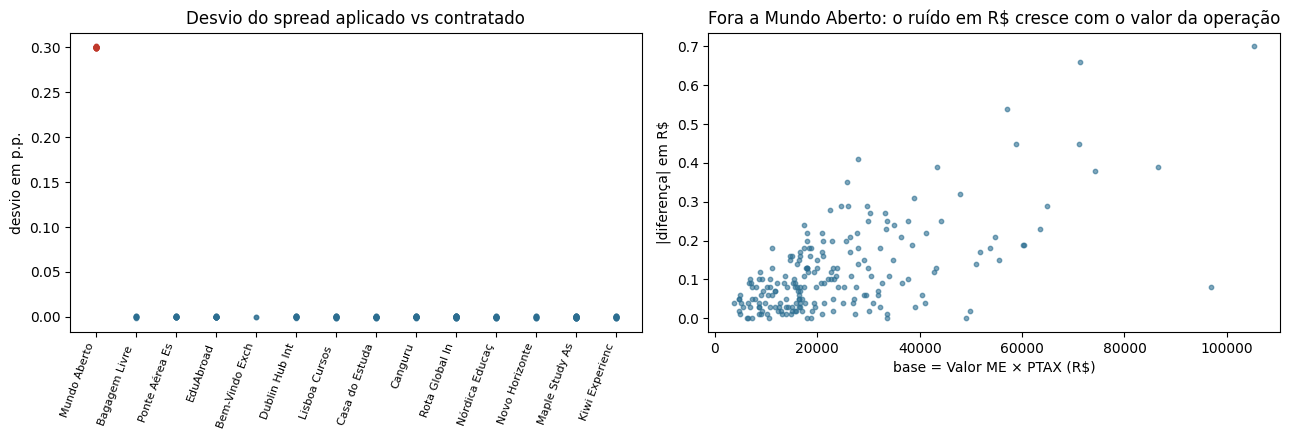

correlação base × |diferença em R$| (fora a Mundo Aberto): 0.64


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ordem = list(resumo.index)
for i, nome in enumerate(ordem):
    x = normais[normais.lojista == nome].desvio_pp
    ax[0].scatter([i] * len(x), x, s=10, alpha=.6, color="#c0392b" if nome == "Mundo Aberto" else "#2c6e91")
ax[0].set_xticks(range(len(ordem))); ax[0].set_xticklabels([n[:14] for n in ordem], rotation=70, ha="right", fontsize=8)
ax[0].set_ylabel("desvio em p.p."); ax[0].set_title("Desvio do spread aplicado vs contratado")
ax[1].scatter(resto.base_brl, resto.abs_brl, s=10, alpha=.6, color="#2c6e91")
ax[1].set_xlabel("base = Valor ME × PTAX (R$)"); ax[1].set_ylabel("|diferença| em R$")
ax[1].set_title("Fora a Mundo Aberto: o ruído em R$ cresce com o valor da operação")
plt.tight_layout(); plt.show()
print(f"correlação base × |diferença em R$| (fora a Mundo Aberto): {resto[['base_brl','abs_brl']].corr().iloc[0,1]:.2f}")

## 2. Qual limite separa o ruído da divergência real?

Premissa de avaliação: a **Mundo Aberto é a única divergência real de spread** em setembro. Ela vem das respostas da
Helena e do cruzamento do time (spread contratado de 1,20% desde julho, aplicado a 1,50%). Com isso, toda operação de
outro lojista que um limite marcar é um **alarme falso**. Se essa premissa estiver errada, o estudo precisa ser refeito.

In [6]:
def varrer(coluna, limites):
    out = []
    for t in limites:
        marcadas = normais[normais[coluna] > t]
        out.append({"limite": t, "marcadas": len(marcadas),
                    "Mundo Aberto (de 23)": int((marcadas.cnpj == MUNDO_ABERTO).sum()),
                    "alarmes falsos": int((marcadas.cnpj != MUNDO_ABERTO).sum())})
    return pd.DataFrame(out)

print("Limite em pontos percentuais (|desvio_pp| > limite):")
display(varrer("abs_pp", [0, 0.0005, 0.001, 0.0015, 0.002, 0.005, 0.01, 0.1]))
print("Limite em reais (|diferença| > limite):")
display(varrer("abs_brl", [0, 0.01, 0.05, 0.10, 0.50, 1.00, 5.00]))

Limite em pontos percentuais (|desvio_pp| > limite):


,limite,marcadas,Mundo Aberto (de 23),alarmes falsos
0,0.0000,228,23,205
1,0.0005,123,23,100
2,0.0010,49,23,26
3,0.0015,25,23,2
4,0.0020,23,23,0
5,0.0050,23,23,0
6,0.0100,23,23,0
7,0.1000,23,23,0


Limite em reais (|diferença| > limite):


,limite,marcadas,Mundo Aberto (de 23),alarmes falsos
0,0.00,220,23,197
1,0.01,210,23,187
2,0.05,158,23,135
3,0.10,110,23,87
4,0.50,26,23,3
5,1.00,23,23,0
6,5.00,23,23,0


In [7]:
ruido_max = resto.abs_pp.max()
real_min = mundo.abs_pp.min()
print(f"maior ruído observado: {ruido_max:.5f} p.p.")
print(f"menor divergência real: {real_min:.5f} p.p. ({real_min / ruido_max:.0f}x o ruído)")
print(f"qualquer limite entre {ruido_max:.4f} e {real_min:.4f} p.p. separa os dois grupos sem erro")
sugerido = D("0.005")
print(f"sugerido: {sugerido} p.p. (≈ {float(sugerido) / ruido_max:.1f}x o maior ruído observado, ainda {real_min / float(sugerido):.0f}x abaixo da divergência real)")

maior ruído observado: 0.00162 p.p.
menor divergência real: 0.29911 p.p. (185x o ruído)
qualquer limite entre 0.0016 e 0.2991 p.p. separa os dois grupos sem erro
sugerido: 0.005 p.p. (≈ 3.1x o maior ruído observado, ainda 60x abaixo da divergência real)


## 3. Recomendação

**Tolerância em pontos percentuais, não em reais.** O ruído da Ponte é proporcional ao valor da operação: em reais ele
chega a R$ 0,70 em operações grandes, e só um limite de R$ 1,00 separaria os grupos em setembro, sem folga para um mês
com operações maiores. Em pontos percentuais o ruído é estável (máximo de 0,0016 p.p.) e há uma folga enorme até a
divergência real (0,299 p.p.).

- **`tolerancia_pp = 0.005`**: 3 vezes o maior ruído observado e 60 vezes menor que a divergência real.
- **`tolerancia_brl = 0`**: mantida sem efeito. Quando as duas existem, a divergência só é reportada se passar das duas.
- Efeito em setembro: 27 divergências, das 224 de antes. São as 23 da Mundo Aberto mais os 4 spreads negativos
  (que entram como divergência por regra já confirmada) e nenhum alarme falso. Ver a verificação abaixo.

**Limites do estudo.** É um único mês, com 14 lojistas. O ruído de 0,0016 p.p. é o observado em setembro e pode mudar.
Por isso a tolerância fica em `config/remessa.json` e deve ser revista quando houver outro mês de dados.

In [8]:
cfg_rec = replace(cfg, tolerancia_pp=sugerido)
linhas_div, _ = divergencias(diferencas, cfg_rec)
rep = pd.DataFrame(linhas_div)
por_grupo = (rep.groupby(["classe", "cnpj"])
             .agg(ops=("ref_origem", "size"), dif_total_brl=("diferenca_brl", lambda s: sum(s))))
print(f"divergências reportadas com tolerancia_pp = {sugerido}: {len(linhas_div)} (eram {len(diferencas)} comparáveis)")
print("NORMAL = spread aplicado diferente do contratado; SPREAD_NEGATIVO = diferença até o contrato (regra confirmada)")
display(por_grupo)

divergências reportadas com tolerancia_pp = 0.005: 27 (eram 232 comparáveis)
NORMAL = spread aplicado diferente do contratado; SPREAD_NEGATIVO = diferença até o contrato (regra confirmada)


ops dif_total_brl
classe          cnpj                             
NORMAL          17217888000111   23       1418.88
SPREAD_NEGATIVO 53857560000123    1      -1001.29
                66564512000199    1       -637.91
                68567965000102    1       -574.91
                95739378000118    1      -1351.87